# Lab Task 05 – Spatial Filtering and Convolution
**Student:** Raja Wajiullah  
**Roll Number:** 2024-SE-28
**University:** The University of Azad Jammu and Kashmir (UAJK)  
**Department:** Software Engineering  
**Course:** Digital Image Processing Lab | **Semester:** Fifth  
**Session:** 2024–28 (SE) | **Instructor:** Engr. Fahad Nisar  
**Assigned:** November 13, 2026 | **Due:** November 20, 2026

## Objective
Implement 2-D convolution from first principles, apply mean, Gaussian, and median filters to noisy real images, verify custom convolution against OpenCV, and compare filtered results against clean originals.

## 1. Imports and setup

In [1]:
import numpy as np, cv2, matplotlib.pyplot as plt
from skimage import data
np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

NumPy: 2.4.6
OpenCV: 5.1.0


## 2. Load camera, coins, and Chelsea as grayscale
The original arrays are kept unchanged; processing functions return separate arrays.

camera: shape=(512, 512), dtype=uint8, range=(0, 255)
coins: shape=(303, 384), dtype=uint8, range=(1, 252)
chelsea: shape=(300, 451), dtype=uint8, range=(4, 194)


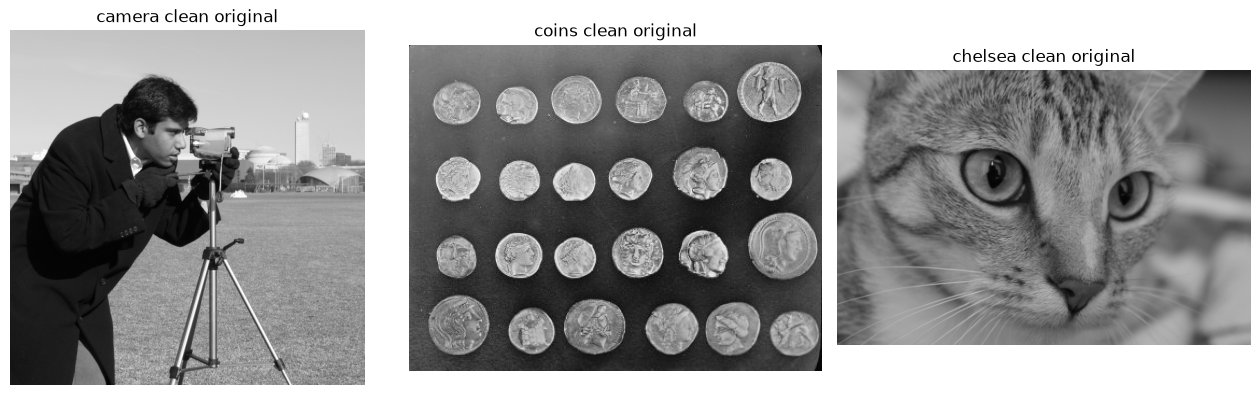

In [2]:
def to_gray_uint8(image):
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    image = np.asarray(image)
    if image.dtype != np.uint8:
        image = np.clip(np.round(image * 255 if image.max() <= 1 else image), 0, 255).astype(np.uint8)
    return image.copy()
originals = {"camera": to_gray_uint8(data.camera()), "coins": to_gray_uint8(data.coins()), "chelsea": to_gray_uint8(data.chelsea())}
for name, image in originals.items():
    print(f"{name}: shape={image.shape}, dtype={image.dtype}, range=({image.min()}, {image.max()})")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, image) in zip(axes, originals.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255); ax.set_title(name + " clean original"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Custom 2-D convolution (R1, R2)
The kernel is flipped in both dimensions (true convolution), reflect padding is used, and calculations are float64.

In [3]:
def conv2d_loop(img, kernel):
    image = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("img and kernel must be 2-D")
    if any(k % 2 == 0 for k in kernel.shape):
        raise ValueError("Kernel dimensions must be odd")
    flipped = kernel[::-1, ::-1]
    ph, pw = kernel.shape[0] // 2, kernel.shape[1] // 2
    padded = np.pad(image, ((ph, ph), (pw, pw)), mode="reflect")
    result = np.zeros(image.shape, dtype=np.float64)
    for r in range(image.shape[0]):
        for c in range(image.shape[1]):
            region = padded[r:r+kernel.shape[0], c:c+kernel.shape[1]]
            result[r, c] = np.sum(region * flipped, dtype=np.float64)
    return result

def to_uint8(image):
    return np.clip(np.round(image), 0, 255).astype(np.uint8)
mean3 = np.ones((3, 3), dtype=np.float64) / 9
test_patch = originals["camera"][:128, :128]
custom_mean = to_uint8(conv2d_loop(test_patch, mean3))
opencv_mean = cv2.blur(test_patch, (3, 3), borderType=cv2.BORDER_REFLECT_101)
difference = np.abs(custom_mean.astype(np.int16) - opencv_mean.astype(np.int16))
print("Maximum difference (uint8 outputs):", int(difference.max()))
print("Mean absolute difference:", float(difference.mean()))
assert difference.max() <= 1

Maximum difference (uint8 outputs): 0
Mean absolute difference: 0.0


## 4. Noise functions (R5)
Both use seed 5, so repeated calls with the same input and parameters reproduce the same noise.

In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    return to_uint8(img.astype(np.float64) + rng.normal(0, sigma, img.shape))

def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    count = int(amount * img.size)
    positions = rng.choice(img.size, count, replace=False)
    half = count // 2
    flat = noisy.reshape(-1)
    flat[positions[:half]] = 255
    flat[positions[half:]] = 0
    return noisy
noisy_images = {}
for name, clean in originals.items():
    noisy_images[(name, "Gaussian")] = add_gaussian_noise(clean, sigma=20, seed=5)
    noisy_images[(name, "Salt-and-pepper")] = add_salt_pepper(clean, amount=0.05, seed=5)
print("Gaussian reproducible:", np.array_equal(noisy_images[("camera", "Gaussian")], add_gaussian_noise(originals["camera"], seed=5)))
print("Salt-pepper reproducible:", np.array_equal(noisy_images[("camera", "Salt-and-pepper")], add_salt_pepper(originals["camera"], seed=5)))
assert np.array_equal(noisy_images[("camera", "Gaussian")], add_gaussian_noise(originals["camera"], seed=5))
assert np.array_equal(noisy_images[("camera", "Salt-and-pepper")], add_salt_pepper(originals["camera"], seed=5))

Gaussian reproducible: True
Salt-pepper reproducible: True


## 5. Noise comparison grid

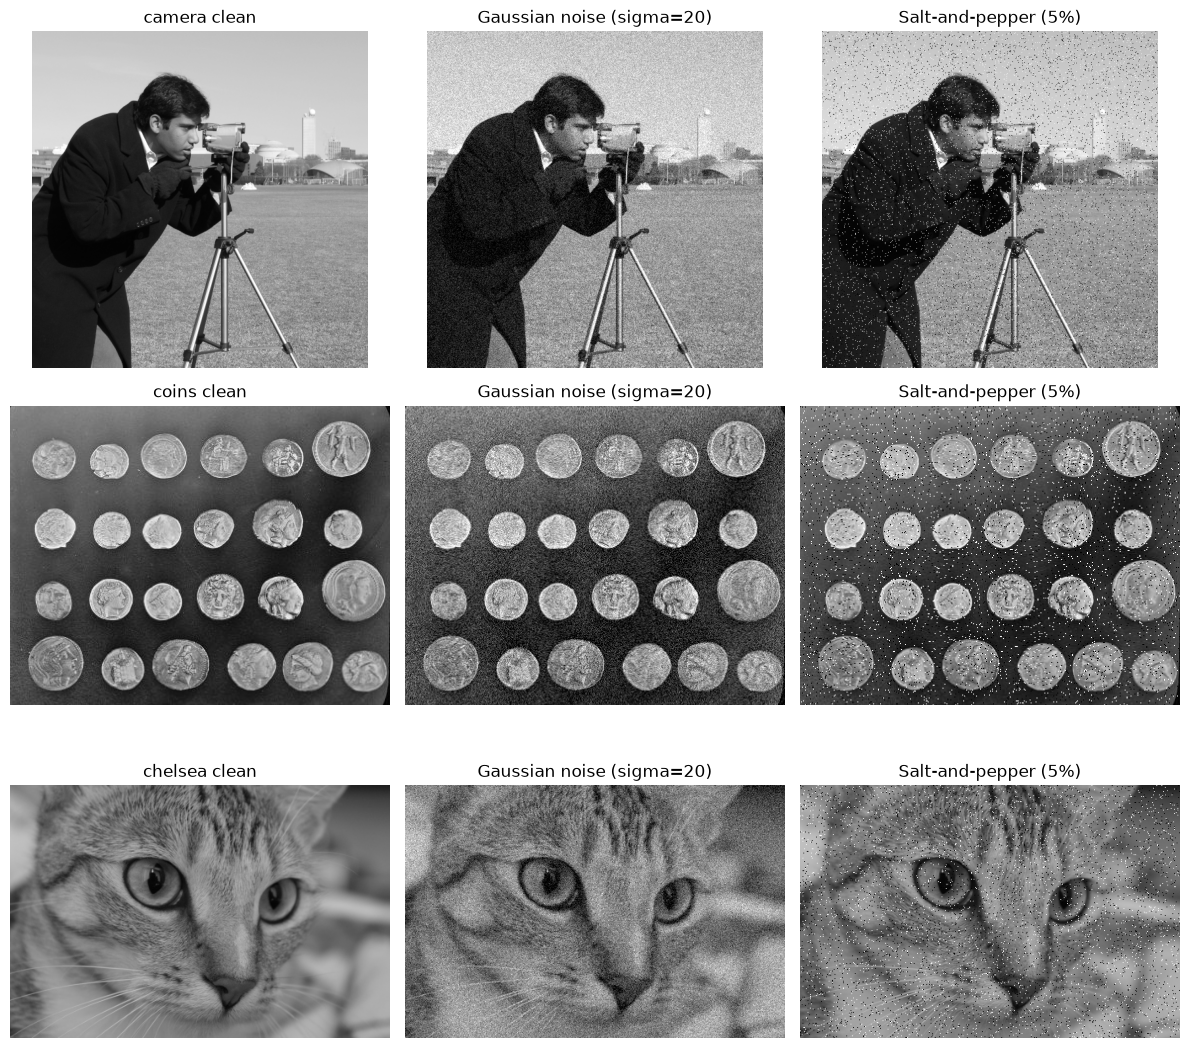

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, (name, clean) in enumerate(originals.items()):
    axes[row, 0].imshow(clean, cmap="gray", vmin=0, vmax=255); axes[row, 0].set_title(name + " clean")
    axes[row, 1].imshow(noisy_images[(name, "Gaussian")], cmap="gray", vmin=0, vmax=255); axes[row, 1].set_title("Gaussian noise (sigma=20)")
    axes[row, 2].imshow(noisy_images[(name, "Salt-and-pepper")], cmap="gray", vmin=0, vmax=255); axes[row, 2].set_title("Salt-and-pepper (5%)")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Mean, Gaussian, and median filters (R1–R4)
Reflect padding is applied. Median is implemented with reflect padding; OpenCV medianBlur is also used as a reference because its border convention can differ.

In [6]:
def mean_kernel(size):
    if size not in (3, 5, 7): raise ValueError("Kernel size must be 3, 5, or 7")
    return np.ones((size, size), dtype=np.float64) / size**2

def gaussian_kernel(size):
    if size not in (3, 5, 7): raise ValueError("Kernel size must be 3, 5, or 7")
    sigma = {3: 1.0, 5: 1.4, 7: 1.8}[size]
    axis = np.arange(size, dtype=np.float64) - size // 2
    vector = np.exp(-(axis**2) / (2*sigma**2))
    kernel = np.outer(vector, vector); kernel /= kernel.sum()
    return kernel

def reflect_median(img, size):
    if size not in (3, 5, 7): raise ValueError("Median size must be 3, 5, or 7 (odd)")
    # Vectorized neighbourhood median with reflect padding (R1); OpenCV reference below.
    from numpy.lib.stride_tricks import sliding_window_view
    image = img.astype(np.float64)
    pad = size // 2
    padded = np.pad(image, ((pad,pad),(pad,pad)), mode="reflect")
    windows = sliding_window_view(padded, (size,size))
    return to_uint8(np.median(windows, axis=(-2,-1)))

for size in (3, 5, 7):
    mk, gk = mean_kernel(size), gaussian_kernel(size)
    print(f"{size}x{size}: mean sum={mk.sum():.12f}, Gaussian sum={gk.sum():.12f}")
    assert np.isclose(mk.sum(), 1) and np.isclose(gk.sum(), 1)
try:
    cv2.medianBlur(originals["camera"], 4)
except cv2.error as exc:
    print("Expected rejection for even kernel 4:", str(exc).splitlines()[0])
else:
    raise AssertionError("OpenCV should reject even median kernel size")

3x3: mean sum=1.000000000000, Gaussian sum=1.000000000000
5x5: mean sum=1.000000000000, Gaussian sum=1.000000000000
7x7: mean sum=1.000000000000, Gaussian sum=1.000000000000
Expected rejection for even kernel 4: OpenCV(5.1.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksize % 2 == 1) && (_src0.dims() <= 2 ) in function 'medianBlur'


## 7. Apply all 3×3 filters to every noisy image
Every output is evaluated against the clean original (R6).

In [7]:
filtered3 = {}
for key, noisy in noisy_images.items():
    filtered3[key] = {
        "Mean": cv2.blur(noisy, (3,3), borderType=cv2.BORDER_REFLECT_101),
        "Gaussian": to_uint8(cv2.GaussianBlur(noisy, (3,3), 0, borderType=cv2.BORDER_REFLECT_101)),
        "Median": reflect_median(noisy, 3),
    }
for key, results in filtered3.items():
    clean = originals[key[0]]
    for output in results.values():
        assert output.shape == clean.shape and output.dtype == np.uint8
        assert output.min() >= 0 and output.max() <= 255
print("All outputs pass shape, uint8, and 0–255 checks.")
median_cv = cv2.medianBlur(noisy_images[("camera", "Salt-and-pepper")], 3)
print("cv2.medianBlur reference:", median_cv.shape, median_cv.dtype)
print("Reflect-padded median result:", filtered3[("camera", "Salt-and-pepper")]["Median"].shape)

All outputs pass shape, uint8, and 0–255 checks.
cv2.medianBlur reference: (512, 512) uint8
Reflect-padded median result: (512, 512)


### Labeled filter comparison: every noisy image

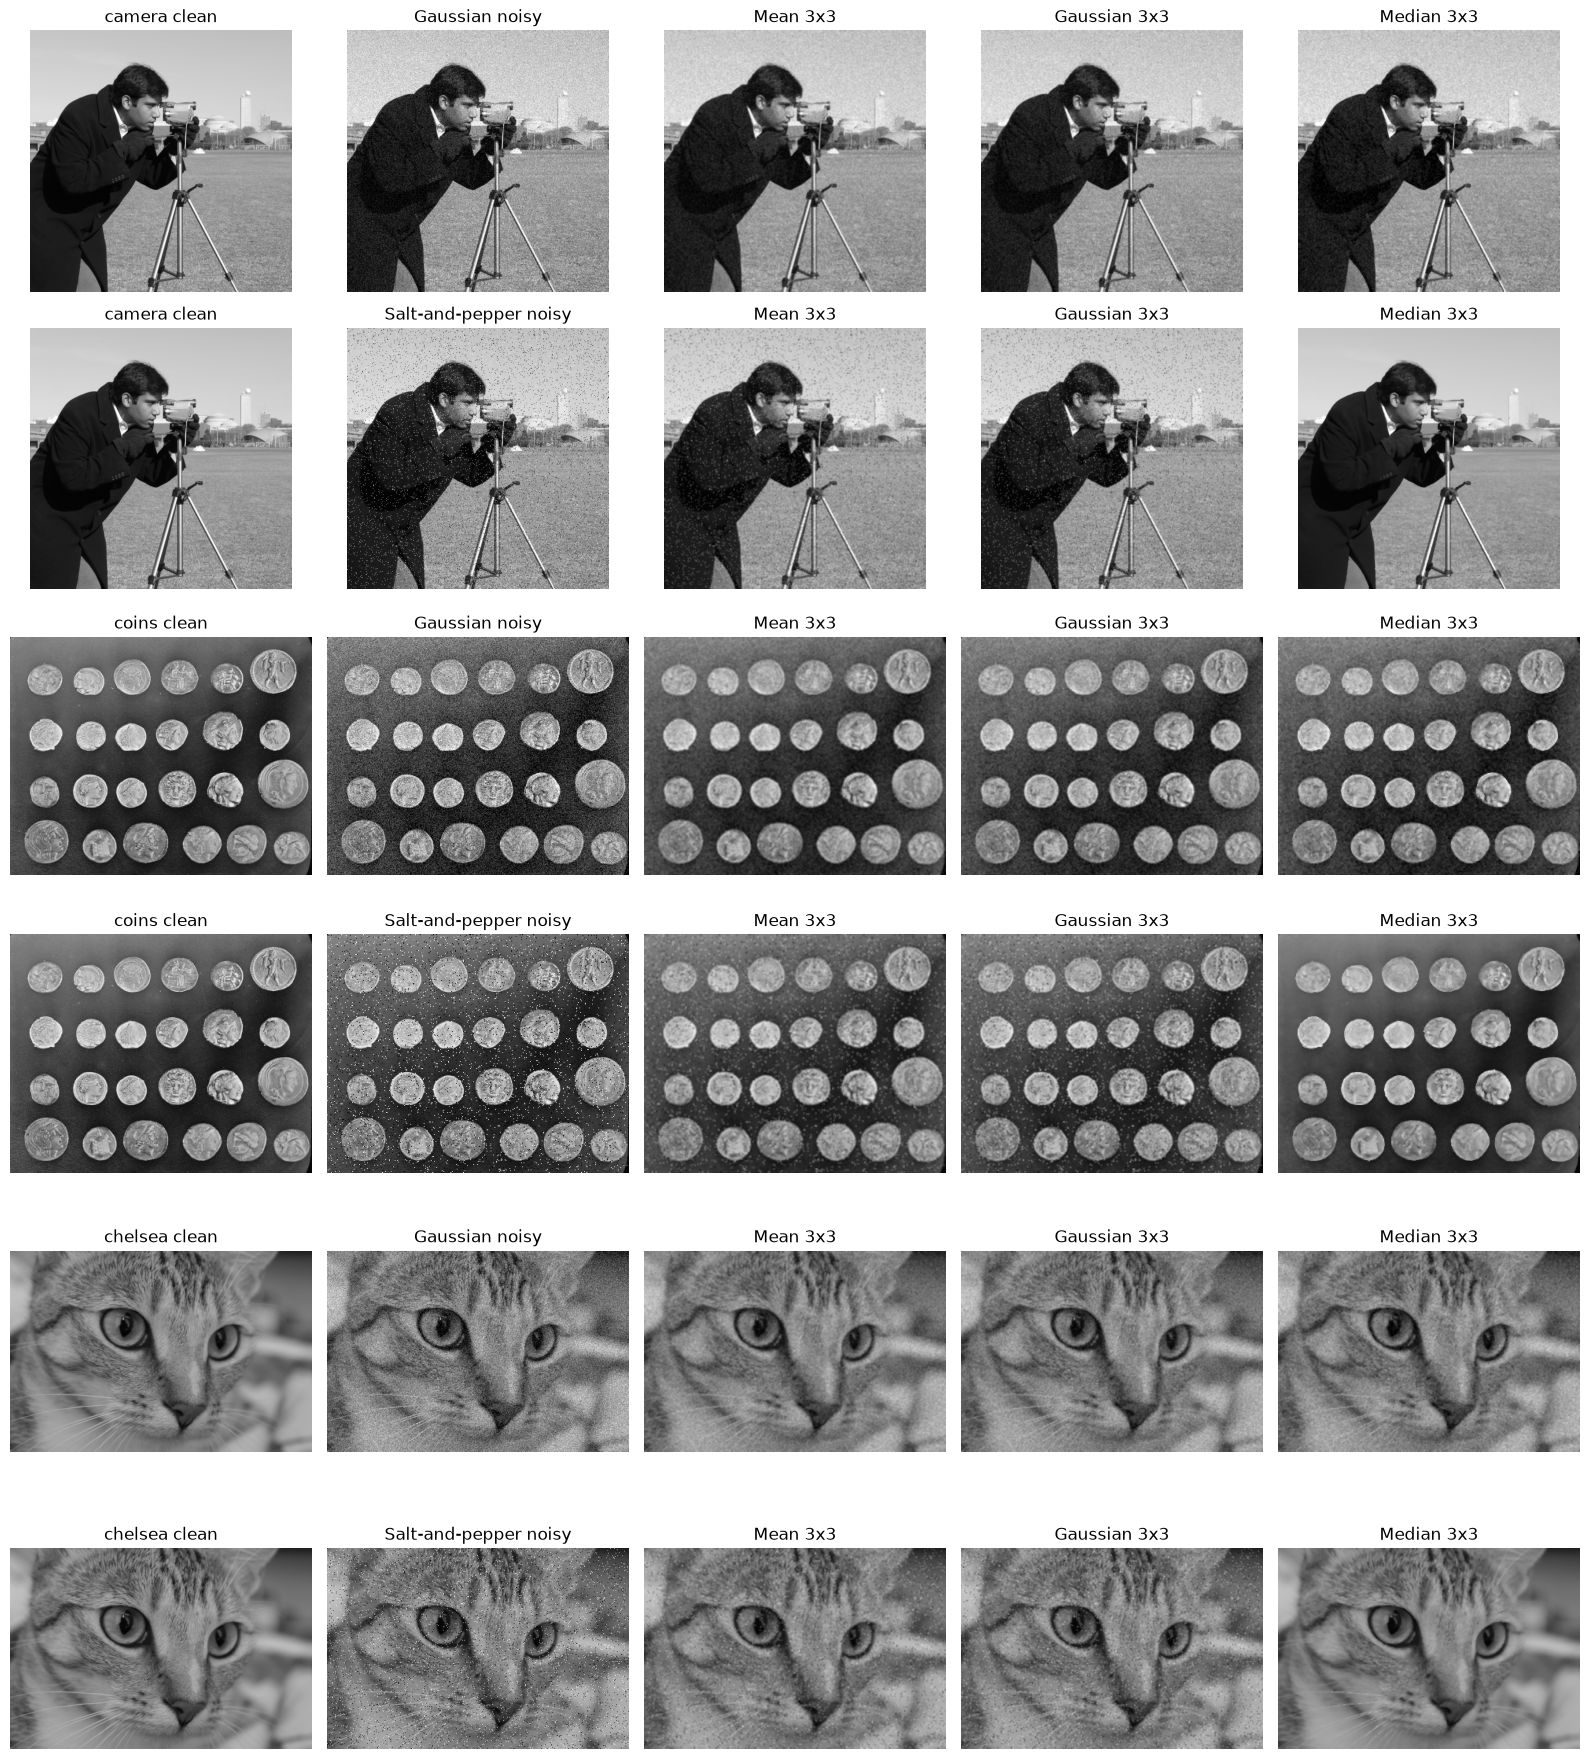

In [8]:
fig, axes = plt.subplots(6, 5, figsize=(16, 18))
for row, ((name, noise), noisy) in enumerate(noisy_images.items()):
    axes[row,0].imshow(originals[name], cmap="gray", vmin=0, vmax=255); axes[row,0].set_title(name+" clean")
    axes[row,1].imshow(noisy, cmap="gray", vmin=0, vmax=255); axes[row,1].set_title(noise+" noisy")
    for col, filt in enumerate(("Mean", "Gaussian", "Median"), 2):
        axes[row,col].imshow(filtered3[(name,noise)][filt], cmap="gray", vmin=0, vmax=255); axes[row,col].set_title(filt+" 3x3")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Kernel-size grid on coins with salt-and-pepper noise

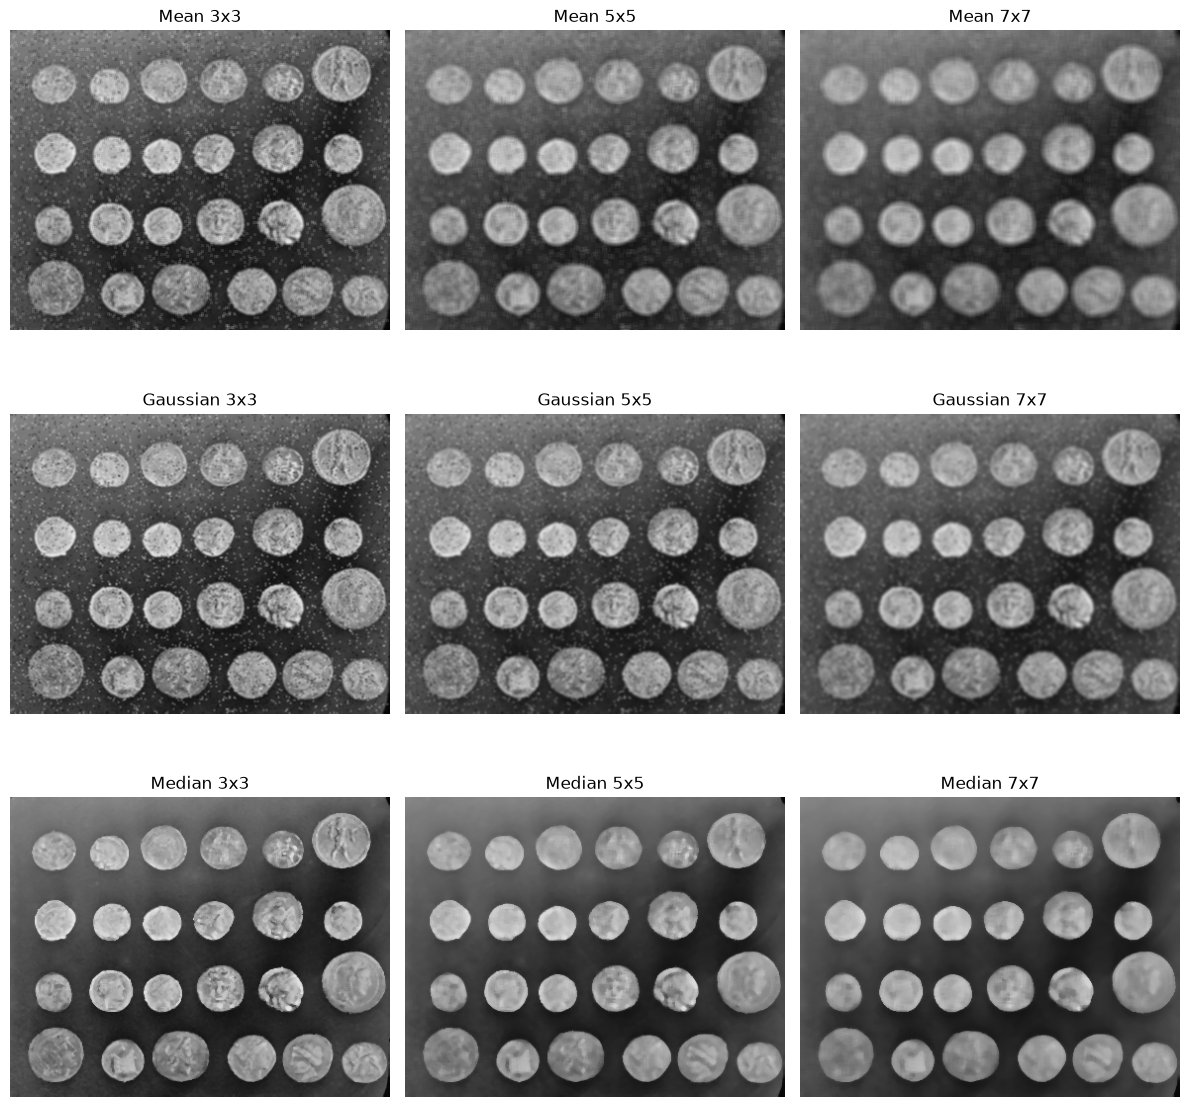

In [9]:
case = noisy_images[("coins", "Salt-and-pepper")]
size_results = {}
for size in (3, 5, 7):
    size_results[("Mean", size)] = cv2.blur(case, (size,size), borderType=cv2.BORDER_REFLECT_101)
    size_results[("Gaussian", size)] = to_uint8(cv2.GaussianBlur(case, (size,size), 0, borderType=cv2.BORDER_REFLECT_101))
    size_results[("Median", size)] = reflect_median(case, size)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, filt in enumerate(("Mean", "Gaussian", "Median")):
    for col, size in enumerate((3, 5, 7)):
        axes[row,col].imshow(size_results[(filt,size)], cmap="gray", vmin=0, vmax=255)
        axes[row,col].set_title(f"{filt} {size}x{size}"); axes[row,col].axis("off")
plt.tight_layout(); plt.show()

## 9. PSNR comparison against clean originals (R6)
Higher PSNR means the output is closer to the clean original in pixel-wise terms.

In [10]:
def psnr(clean, restored):
    mse = np.mean((clean.astype(np.float64)-restored.astype(np.float64))**2)
    return float("inf") if mse == 0 else 10*np.log10(255**2/mse)
for key, results in filtered3.items():
    clean = originals[key[0]]
    print(f"{key[0]} | {key[1]}: noisy={psnr(clean, noisy_images[key]):.3f} dB")
    for name, output in results.items(): print(f"  {name} 3x3: {psnr(clean, output):.3f} dB")

camera | Gaussian: noisy=22.401 dB
  Mean 3x3: 27.369 dB
  Gaussian 3x3: 27.986 dB
  Median 3x3: 26.935 dB
camera | Salt-and-pepper: noisy=17.757 dB
  Mean 3x3: 24.868 dB
  Gaussian 3x3: 24.769 dB
  Median 3x3: 30.137 dB
coins | Gaussian: noisy=22.202 dB
  Mean 3x3: 25.857 dB
  Gaussian 3x3: 26.791 dB
  Median 3x3: 25.985 dB
coins | Salt-and-pepper: noisy=18.089 dB
  Mean 3x3: 24.094 dB
  Gaussian 3x3: 24.349 dB
  Median 3x3: 28.400 dB
chelsea | Gaussian: noisy=22.125 dB
  Mean 3x3: 29.552 dB
  Gaussian 3x3: 29.458 dB
  Median 3x3: 28.276 dB
chelsea | Salt-and-pepper: noisy=18.789 dB
  Mean 3x3: 27.088 dB
  Gaussian 3x3: 26.605 dB
  Median 3x3: 33.893 dB


## 10. Dry-run 1 — Spike response
Neighbourhood: `[[40,40,40],[40,255,40],[40,40,40]]`.

**Mean:** sum = 8×40 + 255 = 575; mean = 575/9 = **63.8889** (rounded **64**).

**Gaussian (1-2-1 / 16):** total kernel weight is 16, centre weight is 4. Weighted sum = 40×12 + 255×4 = 1500; output = 1500/16 = **93.75** (rounded **94**).

**Median:** eight 40 values and one 255; middle value = **40**.

In [11]:
spike = np.array([[40,40,40],[40,255,40],[40,40,40]], dtype=np.uint8)
g3 = np.array([[1,2,1],[2,4,2],[1,2,1]], dtype=np.float64)/16
print("Mean: sum=", spike.sum(), "output=", spike.mean())
print("Gaussian: normalized weighted output=", np.sum(spike*g3))
print("Median=", np.median(spike))
assert np.isclose(spike.sum(), 575) and np.isclose(spike.mean(), 575/9)
assert np.isclose(np.sum(spike*g3), 93.75) and np.isclose(np.median(spike), 40)

Mean: sum= 575 output= 63.888888888888886
Gaussian: normalized weighted output= 93.75
Median= 40.0


## 11. Dry-run 2 — Reflect padding at the top-left
Image: `[[10,20,30],[40,50,60],[70,80,90]]`. NumPy reflect padding gives the top-left neighbourhood:

`[[50,40,50],[20,10,20],[50,40,50]]`

Sum = 330; mean = 330/9 = **36.6667** (rounded **37**).

In [12]:
small = np.array([[10,20,30],[40,50,60],[70,80,90]], dtype=np.float64)
padded = np.pad(small, ((1,1),(1,1)), mode="reflect")
window = padded[:3,:3]
print("Padded image:\n", padded)
print("Top-left neighbourhood:\n", window)
print("sum=", window.sum(), "mean=", window.mean(), "rounded=", round(window.mean()))
assert np.array_equal(window, [[50,40,50],[20,10,20],[50,40,50]])
assert np.isclose(window.sum(), 330) and np.isclose(window.mean(), 330/9)

Padded image:
 [[50. 40. 50. 60. 50.]
 [20. 10. 20. 30. 20.]
 [50. 40. 50. 60. 50.]
 [80. 70. 80. 90. 80.]
 [50. 40. 50. 60. 50.]]
Top-left neighbourhood:
 [[50. 40. 50.]
 [20. 10. 20.]
 [50. 40. 50.]]
sum= 330.0 mean= 36.666666666666664 rounded= 37


## 12. Observations from the figures (R6)
1. **Gaussian noise:** The Gaussian-filtered outputs in Section 7 reduce random grain; median may also help but can produce a different texture. Inspect the camera and Chelsea rows to compare.
2. **Salt-and-pepper noise:** Median in Section 7 is generally best because isolated black/white impulses are replaced by the neighbourhood middle value. Mean and Gaussian spread extreme values across neighbours, leaving smearing and softened detail.
3. **Mean vs Gaussian at sharp edges:** Mean weights all neighbours equally and blurs edges uniformly. Gaussian gives more weight to nearby pixels, often softening an edge less than an equal-size mean filter.
4. **7×7 fine detail:** The larger window suppresses more noise but removes fine texture and small edges; compare 3×3 and 7×7 in Section 8.
5. **Odd kernel sizes:** Odd kernels have a unique centre pixel aligned with the output location. Even kernels lack a single centre, making alignment ambiguous.

## 13. Viva preparation — two answers
**Q1. What is a kernel?** A kernel is a small matrix moved over an image. Pixel values are multiplied by kernel weights and summed to calculate each filtered output pixel.

**Q2. Why does median remove a 255 spike but mean does not?** Median chooses the middle value after sorting the neighbourhood, so a single extreme value often cannot change it. Mean includes every value, so the 255 spike raises the average.

## 14. Rubric checklist
- [x] Custom convolution flips kernel, reflect-pads, uses nested loops and float64, and returns same shape.
- [x] Custom mean output compared with OpenCV; largest difference printed.
- [x] Mean, Gaussian, median for 3×3, 5×5, and 7×7.
- [x] Kernel sums and output shape/dtype/range checked.
- [x] Both noise functions use seed 5 and reproducibility checked.
- [x] Even median size rejection demonstrated.
- [x] Both dry-run calculations shown and asserted in code.
- [x] Noise grid, filter grid, and kernel-size grid displayed.
- [x] Five observations and two viva responses included.

**Submission check:** Restart the kernel and Run All to ensure outputs are fresh and visible before submission.